# 03 · Results
Reproduces every table, statistical test and figure of the article from the saved predictions in `results/`. No model is trained, so the notebook runs on a CPU in a few minutes.

## Setup

In [1]:
import os, sys, glob

REPO = "helsinki-multihorizon-pv"
REPO_URL = f"https://github.com/rhmano/{REPO}.git"

if "google.colab" in sys.modules:
    if not os.path.isdir(REPO):
        os.system(f"git clone -q {REPO_URL}")
    ROOT = os.path.abspath(REPO)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src"))

from multistep_core import *
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
CONFIGS = ("no_nwp", "nwp")
print("Results folder:", CFG.results_dir)

Results folder: /home/claude/rp/helsinki-multihorizon-pv-main/results


## 0. Integrity check

In [2]:
missing = []
for task in TASKS:
    for config in CONFIGS:
        for algo in ALGORITHMS:
            f = os.path.join(CFG.results_dir, f"results_{task}_{config}_{algo}.csv")
            p = os.path.join(CFG.predictions_dir, f"{task}_{config}_{algo}.csv.gz")
            if not (os.path.exists(f) and os.path.exists(p)):
                missing.append(f"{task} | {config} | {algo}")
print("Missing:", missing if missing else "none")
print("Tuning files:", len(glob.glob(os.path.join(CFG.results_dir, "tuning", "*.json"))))
assert not missing

Missing: none
Tuning files: 60


## 1. Data preparation (counts in Sections 3.3 and 4.2)

In [3]:
BASE = prepare_base(CFG)
NWP = load_nwp_table(CFG)
SAMPLES = {task: build_samples(BASE, task, CFG, NWP) for task in TASKS}
for task in TASKS:
    s = SAMPLES[task]
    print(f"{task}: evaluation rows {int(s['eval_ok'].sum()):,} | "
          f"excluded by outage input {int(s['flag_bad_input'].sum()):,} | "
          f"excluded by dataQC {int(s['flag_qc'].sum()):,}")

📂 Preparing the hourly series


   🧾 FMI dataQC = 0: 35 days | additionally excluded measured hours: 655 (daytime: 236) | outage hours also flagged by the rule: 129


   🔁 causal input filling (hours): {'Power_PU_IN': 686, 'GHI_IN': 10, 'Temp_Ambient_IN': 145, 'Humidity_IN': 25, 'Wind_Speed_IN': 74}


   🏷️ Imputed targets: 1,163 | suspected outage hours: 129


   🧱 intraday | 116,557 valid daytime rows | dropped (features) 4,181 | no NWP 25,690


   🧱 dayahead | 19,318 valid daytime rows | dropped (features) 833 | no NWP 4,192


intraday: evaluation rows 116,557 | excluded by outage input 117 | excluded by dataQC 741
dayahead: evaluation rows 19,318 | excluded by outage input 17 | excluded by dataQC 137


## 2. Reference choice (2017 → 2018, test years unseen)

In [4]:
REF = {task: choose_reference(task, SAMPLES[task], CFG) for task in TASKS}

📏 Reference comparison (2017 → 2018, test years unseen): intraday


Reference  Climatology  SmartPersistence          Stronger
Group                                                     
1               13.751             7.234  SmartPersistence
2               13.764            10.837  SmartPersistence
3               13.773            13.875       Climatology
4               13.777            16.697       Climatology
5               13.778            19.140       Climatology
6               13.779            21.119       Climatology
all             13.770            15.564       Climatology


📏 Reference comparison (2017 → 2018, test years unseen): dayahead


Reference  Climatology  SmartPersistence     Stronger
Group                                                
17               2.051             2.727  Climatology
18               5.049             5.775  Climatology
19               8.530            10.302  Climatology
20              12.747            15.416  Climatology
21              15.708            18.383  Climatology
22              17.444            20.624  Climatology
23              17.963            20.526  Climatology
24              18.089            19.951  Climatology
25              17.442            19.241  Climatology
26              15.285            16.956  Climatology
27              13.151            14.212  Climatology
28              10.521            12.042  Climatology
29               6.931            10.192  Climatology
30               3.888            10.025  Climatology
31               2.092             9.253  Climatology
32               1.194             6.085  Climatology
33               0.625      

## 3. Results per horizon (mean over folds)

In [5]:
for task in TASKS:
    for config in CONFIGS:
        for metric in ("nRMSE_pct", "nMAE_pct", "Skill_SmartPersistence", "Skill_Climatology"):
            summary_table(task, config, CFG, metric=metric)

📊 Summary: intraday | no_nwp


nRMSE_pct — mean
Horizon                1       2       3       4       5       6
Model                                                           
Climatology       14.223  14.224  14.223  14.224  14.224  14.224
KNN                7.265   9.424  10.671  11.616  12.227  12.671
LSTM               7.290   9.417  10.788  11.743  12.432  12.883
MLR                7.312   9.926  11.283  12.130  12.657  13.001
RandomForest       6.860   9.037  10.284  11.262  11.941  12.471
SVR                6.857   9.144  10.412  11.375  12.079  12.562
SmartPersistence   7.889  11.650  14.680  17.451  19.863  21.920
XGBoost            6.869   9.079  10.316  11.279  11.977  12.498

nRMSE_pct — std (folds × seeds)
Horizon               1      2      3      4      5      6
Model                                                     
Climatology       0.119  0.119  0.119  0.119  0.120  0.122
KNN               0.088  0.147  0.036  0.084  0.120  0.154
LSTM              0.193  0.225  0.227  0.177  0.266  0.247
MLR  

📊 Summary: intraday | no_nwp


nMAE_pct — mean
Horizon               1      2      3       4       5       6
Model                                                        
Climatology       9.881  9.880  9.879   9.879   9.881   9.881
KNN               4.424  5.974  6.971   7.716   8.212   8.586
LSTM              4.683  6.180  7.202   7.820   8.347   8.709
MLR               4.784  6.986  8.118   8.703   9.025   9.229
RandomForest      3.993  5.620  6.627   7.364   7.874   8.277
SVR               3.776  5.264  6.243   6.935   7.488   7.859
SmartPersistence  4.884  7.686  9.932  11.889  13.558  14.936
XGBoost           4.095  5.728  6.724   7.419   7.959   8.361

nMAE_pct — std (folds × seeds)
Horizon               1      2      3      4      5      6
Model                                                     
Climatology       0.124  0.124  0.123  0.124  0.127  0.128
KNN               0.069  0.115  0.083  0.104  0.156  0.174
LSTM              0.150  0.225  0.261  0.253  0.294  0.231
MLR               0.051  0.133  0.130

📊 Summary: intraday | no_nwp


Skill_SmartPersistence — mean
Horizon               1      2      3      4      5      6
Model                                                     
Climatology      -0.803 -0.221  0.031  0.185  0.284  0.351
KNN               0.079  0.191  0.273  0.334  0.384  0.422
LSTM              0.076  0.192  0.265  0.327  0.375  0.413
MLR               0.073  0.148  0.231  0.305  0.363  0.407
RandomForest      0.130  0.224  0.299  0.355  0.399  0.431
SVR               0.131  0.215  0.291  0.348  0.392  0.427
SmartPersistence  0.000  0.000  0.000  0.000  0.000  0.000
XGBoost           0.129  0.221  0.297  0.354  0.397  0.430

Skill_SmartPersistence — std (folds × seeds)
Horizon               1      2      3      4      5      6
Model                                                     
Climatology       0.029  0.011  0.010  0.012  0.013  0.012
KNN               0.006  0.013  0.012  0.010  0.009  0.007
LSTM              0.020  0.021  0.023  0.020  0.020  0.014
MLR               0.004  0.002  0.004  

... (22 outputs left out)

📊 Summary: dayahead | nwp


Skill_SmartPersistence — mean
Horizon              17     18     19     20     21     22     23     24     25     26     27     28     29     30     31     32     33
Model                                                                                                                                  
Climatology       0.169  0.039  0.063  0.113  0.141  0.138  0.163  0.180  0.177  0.190  0.205  0.238  0.372  0.622  0.770  0.783  0.719
KNN              -1.121  0.075  0.292  0.365  0.391  0.395  0.402  0.372  0.388  0.398  0.401  0.389  0.431  0.577  0.654  0.611  0.129
LSTM             -0.775 -0.066  0.209  0.325  0.381  0.402  0.417  0.385  0.383  0.371  0.370  0.341  0.348  0.469  0.535  0.384 -0.704
MLR               0.017  0.237  0.337  0.364  0.389  0.396  0.426  0.390  0.411  0.409  0.411  0.403  0.372  0.397  0.421  0.536  0.515
RandomForest      0.418  0.328  0.366  0.382  0.419  0.415  0.435  0.408  0.412  0.407  0.418  0.437  0.512  0.676  0.768  0.781  0.736
SVR               

📊 Summary: dayahead | nwp


Skill_Climatology — mean
Horizon              17     18     19     20     21     22     23     24     25     26     27     28     29     30     31     32     33
Model                                                                                                                                  
Climatology       0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
KNN              -1.566  0.038  0.245  0.284  0.291  0.299  0.286  0.235  0.255  0.256  0.246  0.198  0.091 -0.121 -0.529 -0.812 -2.172
LSTM             -1.164 -0.108  0.160  0.243  0.281  0.308  0.306  0.254  0.252  0.223  0.208  0.134 -0.044 -0.408 -1.029 -1.773 -4.899
MLR              -0.183  0.207  0.294  0.283  0.289  0.300  0.314  0.258  0.284  0.270  0.259  0.216 -0.002 -0.594 -1.537 -1.142 -0.713
RandomForest      0.297  0.301  0.325  0.304  0.323  0.322  0.325  0.280  0.285  0.268  0.267  0.259  0.222  0.145 -0.001 -0.012  0.063
SVR               0.000

## 4. Pooled skill (all horizons) and solar-elevation sensitivity

In [6]:
for task in TASKS:
    for config in CONFIGS:
        pooled_skill_table(task, config, CFG)
        pooled_skill_table(task, config, CFG, min_elev_deg=10)

📊 Pooled skill: intraday_no_nwp  (rows: 24,774 per fold)


                 nRMSE_pct        Skill_SP        Skill_Clim       
                      mean    std     mean    std       mean    std
Model                                                              
RandomForest        10.500  0.114    0.357  0.014      0.263  0.007
XGBoost             10.529  0.125    0.355  0.010      0.261  0.005
SVR                 10.603  0.191    0.350  0.009      0.256  0.009
KNN                 10.821  0.065    0.337  0.010      0.241  0.007
LSTM                10.939  0.180    0.330  0.018      0.232  0.016
MLR                 11.239  0.096    0.311  0.007      0.211  0.004
Climatology         14.253  0.086    0.127  0.012      0.000  0.000
SmartPersistence    16.324  0.294    0.000  0.000     -0.145  0.016


📊 Pooled skill: intraday_no_nwp_elev10  (rows: 18,462 per fold)


                 nRMSE_pct        Skill_SP        Skill_Clim       
                      mean    std     mean    std       mean    std
Model                                                              
RandomForest        12.002  0.095    0.356  0.015      0.263  0.007
XGBoost             12.021  0.174    0.356  0.011      0.262  0.005
SVR                 12.117  0.262    0.350  0.010      0.256  0.009
KNN                 12.330  0.185    0.339  0.010      0.243  0.007
LSTM                12.445  0.218    0.333  0.018      0.236  0.015
MLR                 12.711  0.196    0.319  0.008      0.219  0.003
Climatology         16.283  0.201    0.127  0.013      0.000  0.000
SmartPersistence    18.658  0.500    0.000  0.000     -0.146  0.017


📊 Pooled skill: intraday_nwp  (rows: 24,774 per fold)


                 nRMSE_pct        Skill_SP        Skill_Clim       
                      mean    std     mean    std       mean    std
Model                                                              
RandomForest         8.334  0.193    0.489  0.021      0.415  0.017
XGBoost              8.436  0.178    0.483  0.020      0.408  0.016
SVR                  8.595  0.236    0.473  0.024      0.397  0.019
LSTM                 8.740  0.644    0.464  0.044      0.387  0.048
MLR                  8.872  0.150    0.456  0.018      0.377  0.014
KNN                  8.874  0.183    0.456  0.019      0.377  0.017
Climatology         14.253  0.086    0.127  0.012      0.000  0.000
SmartPersistence    16.324  0.294    0.000  0.000     -0.145  0.016


... (6 outputs left out)

📊 Pooled skill: dayahead_nwp  (rows: 4,128 per fold)


                 nRMSE_pct        Skill_SP        Skill_Clim       
                      mean    std     mean    std       mean    std
Model                                                              
XGBoost             10.060  0.223    0.424  0.038      0.294  0.018
RandomForest        10.064  0.256    0.424  0.039      0.294  0.021
SVR                 10.385  0.312    0.406  0.043      0.271  0.025
MLR                 10.473  0.287    0.401  0.042      0.265  0.024
KNN                 10.610  0.291    0.393  0.034      0.256  0.023
LSTM                10.847  0.801    0.379  0.063      0.239  0.059
Climatology         14.256  0.067    0.185  0.033      0.000  0.000
SmartPersistence    17.509  0.782    0.000  0.000     -0.228  0.050


📊 Pooled skill: dayahead_nwp_elev10  (rows: 3,077 per fold)


                 nRMSE_pct        Skill_SP        Skill_Clim       
                      mean    std     mean    std       mean    std
Model                                                              
XGBoost             11.487  0.180    0.424  0.038      0.294  0.018
RandomForest        11.506  0.241    0.423  0.039      0.293  0.021
SVR                 11.853  0.277    0.406  0.043      0.272  0.025
MLR                 11.912  0.283    0.403  0.042      0.268  0.023
KNN                 12.017  0.376    0.398  0.035      0.262  0.022
LSTM                12.229  0.895    0.387  0.063      0.249  0.058
Climatology         16.279  0.195    0.185  0.033      0.000  0.000
SmartPersistence    20.002  1.062    0.000  0.000     -0.228  0.050


## 5. R²

In [7]:
R2 = r2_table(CFG)

Task                   dayahead                      intraday               
Config                   no_nwp            nwp         no_nwp            nwp
Model                                                                       
Climatology         0.65 ± 0.02  0.649 ± 0.021   0.65 ± 0.023   0.65 ± 0.022
KNN               0.669 ± 0.017  0.805 ± 0.005  0.798 ± 0.009  0.864 ± 0.006
LSTM              0.668 ± 0.019  0.796 ± 0.025  0.794 ± 0.008  0.868 ± 0.016
MLR                0.68 ± 0.016   0.81 ± 0.014  0.783 ± 0.013  0.864 ± 0.007
RandomForest      0.684 ± 0.011  0.825 ± 0.014   0.81 ± 0.015   0.88 ± 0.009
SVR               0.671 ± 0.029  0.813 ± 0.017  0.806 ± 0.016  0.872 ± 0.011
SmartPersistence  0.471 ± 0.047  0.472 ± 0.048  0.541 ± 0.027   0.54 ± 0.026
XGBoost            0.68 ± 0.008  0.825 ± 0.015  0.809 ± 0.015  0.877 ± 0.008


## 6. Significance: Diebold–Mariano (HLN) with Holm correction
`best_set_*.csv`: the algorithm with the lowest RMSE and the algorithms indistinguishable from it.

In [8]:
DM = {}
for task in TASKS:
    for config in CONFIGS:
        DM[(task, config)] = pairwise_dm(task, config, CFG)
        best_set(DM[(task, config)], task, config, CFG)

🏁 Best set (Holm, α = 0.05): intraday | no_nwp


Group         Best  nRMSE_best       Indistinguishable
  all RandomForest      10.489            XGBoost, SVR
    1          SVR       6.853   RandomForest, XGBoost
    2 RandomForest       9.037            XGBoost, SVR
    3 RandomForest      10.288            XGBoost, SVR
    4 RandomForest      11.270            XGBoost, SVR
    5 RandomForest      11.953      XGBoost, SVR, LSTM
    6 RandomForest      12.486 XGBoost, SVR, KNN, LSTM


🏁 Best set (Holm, α = 0.05): intraday | nwp


Group         Best  nRMSE_best Indistinguishable
  all RandomForest       8.329                 —
    1 RandomForest       6.460      SVR, XGBoost
    2 RandomForest       7.853              LSTM
    3 RandomForest       8.371              LSTM
    4 RandomForest       8.711              LSTM
    5 RandomForest       9.010              LSTM
    6 RandomForest       9.265                 —


🏁 Best set (Holm, α = 0.05): dayahead | no_nwp


Group         Best  nRMSE_best                     Indistinguishable
  all RandomForest      13.548               MLR, XGBoost, SVR, LSTM
   17 RandomForest       1.786                                     —
   18 RandomForest       4.955                    SVR, XGBoost, LSTM
   19          SVR       8.890      RandomForest, XGBoost, MLR, LSTM
   20          SVR      12.410 RandomForest, XGBoost, KNN, MLR, LSTM
   21 RandomForest      15.386          SVR, KNN, XGBoost, MLR, LSTM
   22 RandomForest      17.487          XGBoost, KNN, MLR, SVR, LSTM
   23 RandomForest      17.949               XGBoost, MLR, LSTM, SVR
   24          MLR      18.507      RandomForest, XGBoost, LSTM, SVR
   25          MLR      17.436           XGBoost, RandomForest, LSTM
   26          MLR      15.281           XGBoost, RandomForest, LSTM
   27          MLR      12.940      RandomForest, XGBoost, KNN, LSTM
   28          MLR      10.227      RandomForest, XGBoost, SVR, LSTM
   29          SVR       6.826    

🏁 Best set (Holm, α = 0.05): dayahead | nwp


Group         Best  nRMSE_best                     Indistinguishable
  all      XGBoost      10.060                          RandomForest
   17 RandomForest       1.288                                     —
   18 RandomForest       3.631                          XGBoost, SVR
   19      XGBoost       6.459                     RandomForest, SVR
   20 RandomForest       9.377          XGBoost, SVR, MLR, KNN, LSTM
   21 RandomForest      11.189                    XGBoost, SVR, LSTM
   22      XGBoost      12.516               RandomForest, LSTM, KNN
   23      XGBoost      12.749          RandomForest, MLR, SVR, LSTM
   24      XGBoost      13.827               RandomForest, SVR, LSTM
   25 RandomForest      13.135          MLR, XGBoost, SVR, KNN, LSTM
   26          MLR      11.856 RandomForest, XGBoost, KNN, SVR, LSTM
   27 RandomForest      10.017          XGBoost, MLR, KNN, SVR, LSTM
   28      XGBoost       7.898                          RandomForest
   29 RandomForest       5.433    

## 7. Contribution of the weather forecast (nwp vs no_nwp)

In [9]:
NWP_GAIN = {task: nwp_gain_dm(task, CFG) for task in TASKS}

🌦️ NWP gain (DM, Holm): intraday


    Task Group        Model  N_days       DM   p  nRMSE_no  nRMSE_nwp  Gain_pct  p_holm
intraday   all          KNN    1030 -10.3005 0.0   10.8069     8.8587   18.0276     0.0
intraday   all         LSTM    1023  -8.7456 0.0   10.8951     8.7966   19.2609     0.0
intraday   all          MLR    1030 -10.9329 0.0   11.2259     8.8558   21.1133     0.0
intraday   all RandomForest    1030 -10.4558 0.0   10.4826     8.3156   20.6732     0.0
intraday   all          SVR    1030  -9.2472 0.0   10.5890     8.5729   19.0394     0.0
intraday   all      XGBoost    1030 -10.0984 0.0   10.5129     8.4166   19.9404     0.0


🌦️ NWP gain (DM, Holm): dayahead


    Task Group        Model  N_days       DM   p  nRMSE_no  nRMSE_nwp  Gain_pct  p_holm
dayahead   all          KNN    1019  -9.9212 0.0   13.8980    10.6295   23.5176     0.0
dayahead   all         LSTM    1008  -7.2388 0.0   13.8703    11.0876   20.0624     0.0
dayahead   all          MLR    1019  -9.4393 0.0   13.6355    10.4675   23.2336     0.0
dayahead   all RandomForest    1019  -9.7040 0.0   13.5643    10.0602   25.8327     0.0
dayahead   all          SVR    1019  -8.2609 0.0   13.8328    10.3737   25.0062     0.0
dayahead   all      XGBoost    1019 -10.2648 0.0   13.6612    10.0559   26.3903     0.0


## 8. Annual accuracy of MEPS irradiance forecasts (diagnostic)

In [10]:
NWPQ = nwp_quality_by_year(BASE, NWP, CFG)

🌦️ Annual accuracy of MEPS irradiance forecasts


              Lead  Year         Scheme    n  RMSE_Wm2  Bias_Wm2  nRMSE_pct_meanGHI     r
 intraday (4–33 h)  2017 full_backup+pp 5465     108.7     -34.1               48.5 0.873
 intraday (4–33 h)  2018 full_backup+pp 5582     115.5     -51.0               44.5 0.891
 intraday (4–33 h)  2019 full_backup+pp 5555     108.2     -35.8               43.6 0.893
 intraday (4–33 h)  2020 full_backup+pp  240      23.6      -3.3               59.3 0.819
 intraday (4–33 h)  2020       meps_det 5348     109.2     -42.6               42.0 0.898
 intraday (4–33 h)  2021       meps_det 5605     110.4     -39.0               45.7 0.884
dayahead (24–47 h)  2017 full_backup+pp 4013     114.7     -37.3               50.5 0.865
dayahead (24–47 h)  2018 full_backup+pp 4107     124.7     -56.3               47.5 0.878
dayahead (24–47 h)  2019 full_backup+pp 4087     117.5     -39.2               46.5 0.879
dayahead (24–47 h)  2020 full_backup+pp  200      25.6      -6.5               55.6 0.849
dayahead (

## 9. Selected hyperparameters

In [11]:
TUNING = tuning_summary(CFG)

    Task Config        Model  Test_year  Validation_year                                                     Selected
intraday no_nwp          KNN       2019             2018                   {'n_neighbors': 25, 'weights': 'distance'}
intraday no_nwp          KNN       2020             2019                   {'n_neighbors': 50, 'weights': 'distance'}
intraday no_nwp          KNN       2021             2020                   {'n_neighbors': 50, 'weights': 'distance'}
intraday no_nwp RandomForest       2019             2018                {'max_features': 0.5, 'min_samples_leaf': 20}
intraday no_nwp RandomForest       2020             2019                {'max_features': 0.5, 'min_samples_leaf': 20}
intraday no_nwp RandomForest       2021             2020              {'max_features': 'sqrt', 'min_samples_leaf': 5}
intraday no_nwp      XGBoost       2019             2018 {'max_depth': 3, 'learning_rate': 0.03, 'n_estimators': 300}
intraday no_nwp      XGBoost       2020             2019

## 10. Article figures (Figures 1 and 2)
Mean nRMSE over test years (and LSTM seeds), as a percentage of nominal power. Shaded area: range between the lowest and highest error of the six algorithms; line: RF. Figure 1 shows both configurations in one panel; Figure 2 uses one panel per configuration.

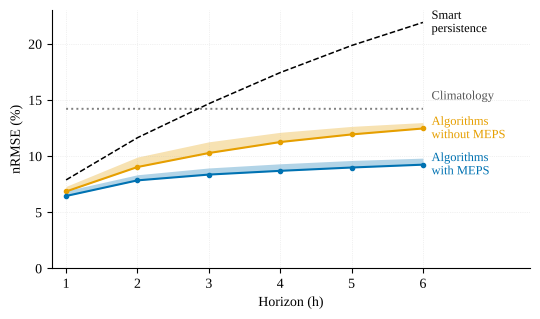

Saved: /home/claude/rp/helsinki-multihorizon-pv-main/results/Fig1_intraday_nRMSE.png


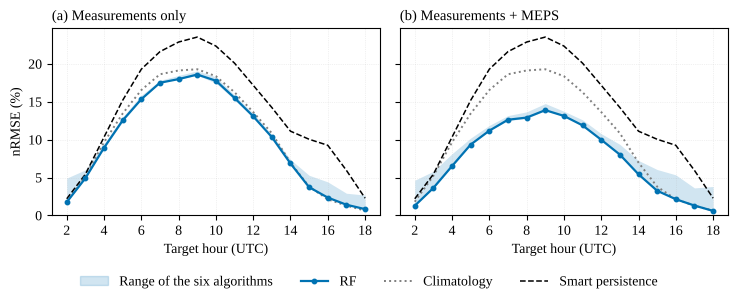

Saved: /home/claude/rp/helsinki-multihorizon-pv-main/results/Fig2_dayahead_nRMSE.png


In [12]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.rcParams.update({"font.family": "serif",
                     "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10})
BLUE, ORANGE = "#0072B2", "#E69F00"


def mean_by_horizon(task, config):
    r = load_results(task, config, CFG)
    return r.groupby(["Model", "Horizon"])["nRMSE_pct"].mean().unstack("Horizon")


def save(fig, fname):
    out = os.path.join(CFG.results_dir, fname)
    fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    print("Saved:", out)


def figure_intraday(fname):
    fig, ax = plt.subplots(figsize=(5.5, 3.3))
    for config, col, lab in (("no_nwp", ORANGE, "without MEPS"), ("nwp", BLUE, "with MEPS")):
        g = mean_by_horizon("intraday", config)
        x = g.columns.to_numpy()
        a = g.loc[list(ALGORITHMS)]
        ax.fill_between(x, a.min().to_numpy(), a.max().to_numpy(), color=col, alpha=0.30, linewidth=0)
        ax.plot(x, g.loc["RandomForest"], color=col, marker="o", ms=3, lw=1.5)
        ax.text(x[-1] + 0.12, g.loc["RandomForest", x[-1]], f"Algorithms\n{lab}", va="center", fontsize=9, color=col)
    ax.plot(x, g.loc["Climatology"], color="#7F7F7F", ls=":", lw=1.4)
    ax.text(x[-1] + 0.12, g.loc["Climatology", x[-1]] + 0.6, "Climatology", va="bottom", fontsize=9, color="#555555")
    ax.plot(x, g.loc["SmartPersistence"], color="black", ls="--", lw=1.1)
    ax.text(x[-1] + 0.12, g.loc["SmartPersistence", x[-1]], "Smart\npersistence", va="center", fontsize=9)
    ax.set_xlim(0.8, 7.5)
    ax.set_xticks(x)
    ax.set_ylim(0, 23)
    ax.grid(alpha=0.35, ls=":", lw=0.5)
    ax.set_xlabel("Horizon (h)")
    ax.set_ylabel("nRMSE (%)")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    fig.tight_layout()
    save(fig, fname)


def figure_dayahead(fname):
    fig, axes = plt.subplots(1, 2, figsize=(7.48, 3.0), sharey=True)
    for ax, config, title in zip(axes, CONFIGS, ("(a) Measurements only", "(b) Measurements + MEPS")):
        g = mean_by_horizon("dayahead", config)
        xs = g.columns.to_numpy() - 15
        a = g.loc[list(ALGORITHMS)]
        ax.fill_between(xs, a.min().to_numpy(), a.max().to_numpy(), color=BLUE, alpha=0.18, linewidth=0)
        ax.plot(xs, g.loc["Climatology"], color="#7F7F7F", ls=":", lw=1.4)
        ax.plot(xs, g.loc["SmartPersistence"], color="black", ls="--", lw=1.1)
        ax.plot(xs, g.loc["RandomForest"], color=BLUE, marker="o", ms=3.2, lw=1.6)
        ax.set_title(title, loc="left", fontsize=10.5)
        ax.set_xlabel("Target hour (UTC)")
        ax.set_xticks(xs[::2])
        ax.grid(alpha=0.35, ls=":", lw=0.5)
        ax.set_ylim(bottom=0)
    axes[0].set_ylabel("nRMSE (%)")
    handles = [Patch(color=BLUE, alpha=0.18, label="Range of the six algorithms"),
               Line2D([], [], color=BLUE, marker="o", ms=3.2, lw=1.6, label="RF"),
               Line2D([], [], color="#7F7F7F", ls=":", lw=1.4, label="Climatology"),
               Line2D([], [], color="black", ls="--", lw=1.1, label="Smart persistence")]
    fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    save(fig, fname)


figure_intraday("Fig1_intraday_nRMSE.png")
figure_dayahead("Fig2_dayahead_nRMSE.png")

## 11. Saved files

In [13]:
for f in sorted(glob.glob(os.path.join(CFG.results_dir, "*.csv")) + glob.glob(os.path.join(CFG.results_dir, "*.png"))):
    print(os.path.basename(f))

Fig1_intraday_nRMSE.png
Fig2_dayahead_nRMSE.png
best_set_dayahead_no_nwp.csv
best_set_dayahead_nwp.csv
best_set_intraday_no_nwp.csv
best_set_intraday_nwp.csv
dm_nwp_gain_dayahead.csv
dm_nwp_gain_intraday.csv
dm_pairs_dayahead_no_nwp.csv
dm_pairs_dayahead_nwp.csv
dm_pairs_intraday_no_nwp.csv
dm_pairs_intraday_nwp.csv
learning_curve_nwp_2021.csv
nwp_quality_by_year.csv
pooled_skill_dayahead_no_nwp.csv
pooled_skill_dayahead_no_nwp_elev10.csv
pooled_skill_dayahead_nwp.csv
pooled_skill_dayahead_nwp_elev10.csv
pooled_skill_intraday_no_nwp.csv
pooled_skill_intraday_no_nwp_elev10.csv
pooled_skill_intraday_nwp.csv
pooled_skill_intraday_nwp_elev10.csv
r2_all_algorithms.csv
reference_choice_dayahead.csv
reference_choice_intraday.csv
results_dayahead_no_nwp_KNN.csv
results_dayahead_no_nwp_LSTM.csv
results_dayahead_no_nwp_MLR.csv
results_dayahead_no_nwp_RandomForest.csv
results_dayahead_no_nwp_References.csv
results_dayahead_no_nwp_SVR.csv
results_dayahead_no_nwp_XGBoost.csv
results_dayahead_nwp_KN